### 1. Mengimport Library yang Dibutuhkan


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### 2. Membaca dan Memeriksa Dataset


In [ ]:
dataset = pd.read_csv('/content/Sales Transaction v.4a.csv')
dataset.head()

,TransactionNo,Date,ProductNo,ProductName,Price,Quantity,CustomerNo,Country
0,581482,12/9/2019,22485,Set Of 2 Wooden Market Crates,21.47,12,17490.0,United Kingdom
1,581475,12/9/2019,22596,Christmas Star Wish List Chalkboard,10.65,36,13069.0,United Kingdom
2,581475,12/9/2019,23235,Storage Tin Vintage Leaf,11.53,12,13069.0,United Kingdom
3,581475,12/9/2019,23272,Tree T-Light Holder Willie Winkie,10.65,12,13069.0,United Kingdom
4,581475,12/9/2019,23239,Set Of 4 Knick Knack Tins Poppies,11.94,6,13069.0,United Kingdom


In [ ]:
print(dataset.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 536350 entries, 0 to 536349
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   TransactionNo  536350 non-null  object 
 1   Date           536350 non-null  object 
 2   ProductNo      536350 non-null  object 
 3   ProductName    536350 non-null  object 
 4   Price          536350 non-null  float64
 5   Quantity       536350 non-null  int64  
 6   CustomerNo     536295 non-null  float64
 7   Country        536350 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 32.7+ MB
None


### 3. Identifikasi Data Kosong (Null/Missing Values)


In [ ]:
print(dataset.isnull().sum())

TransactionNo     0
Date              0
ProductNo         0
ProductName       0
Price             0
Quantity          0
CustomerNo       55
Country           0
dtype: int64


In [ ]:
dataset = dataset.dropna(subset=['CustomerNo']).copy()

In [ ]:
dataset['CustomerNo'] = dataset['CustomerNo'].astype('int64')

### 4. Transformasi Tipe Data dan Pembersihan Nilai Negatif

Mengubah kolom tanggal menjadi format datetime

In [ ]:
dataset['Date'] = pd.to_datetime(dataset['Date'])

Menghapus kolom negatif

In [ ]:
dataset = dataset[dataset['Quantity'] > 0]

### 5. Segmentasi Produk Berdasarkan Tingkat Permintaan
Melakukan pengelompokan produk ke dalam 5 kategori permintaan (dari *Very rarely purchased* hingga *Very frequently purchased*) menggunakan metode kuantil (qcut) berdasarkan total unit terjual.

In [ ]:
produk = (
    dataset.groupby(["ProductNo", "ProductName"], as_index=False)
    .agg(
        Total_Unit_Terjual=("Quantity", "sum"),
        Jumlah_Transaksi=("TransactionNo", "nunique")
    )
)

In [ ]:
produk["Peringkat"] = produk["Total_Unit_Terjual"].rank(
    method="first"
)

label_produk = [
    "Very rarely purchased",
    "Rarely purchased",
    "Moderately purchased",
    "Frequently purchased",
    "Very frequently purchased"
]

produk["Kelompok_Permintaan"] = pd.qcut(
    produk["Peringkat"],
    q=5,
    labels=label_produk
)

In [ ]:
ringkasan_produk = (
    produk.groupby("Kelompok_Permintaan", observed=False)
    .agg(
        Jumlah_Produk=("ProductNo", "count"),
        Minimum_Unit=("Total_Unit_Terjual", "min"),
        Median_Unit=("Total_Unit_Terjual", "median"),
        Maksimum_Unit=("Total_Unit_Terjual", "max")
    )
    .reset_index()
)

ringkasan_produk["Persentase_Produk"] = (
    ringkasan_produk["Jumlah_Produk"] /
    len(produk) * 100
).round(2)

print("Ringkasan Pengelompokan Produk")
print(ringkasan_produk.to_string(index=False))

Ringkasan Pengelompokan Produk
      Kelompok_Permintaan  Jumlah_Produk  Minimum_Unit  Median_Unit  Maksimum_Unit  Persentase_Produk
    Very rarely purchased            751             1         12.0             40              20.01
         Rarely purchased            750            40        106.0            226              19.98
     Moderately purchased            751           226        422.0            724              20.01
     Frequently purchased            750           725       1173.0           1933              19.98
Very frequently purchased            751          1933       3731.0          80995              20.01


### 6. Visualisasi Distribusi Kategori Produk


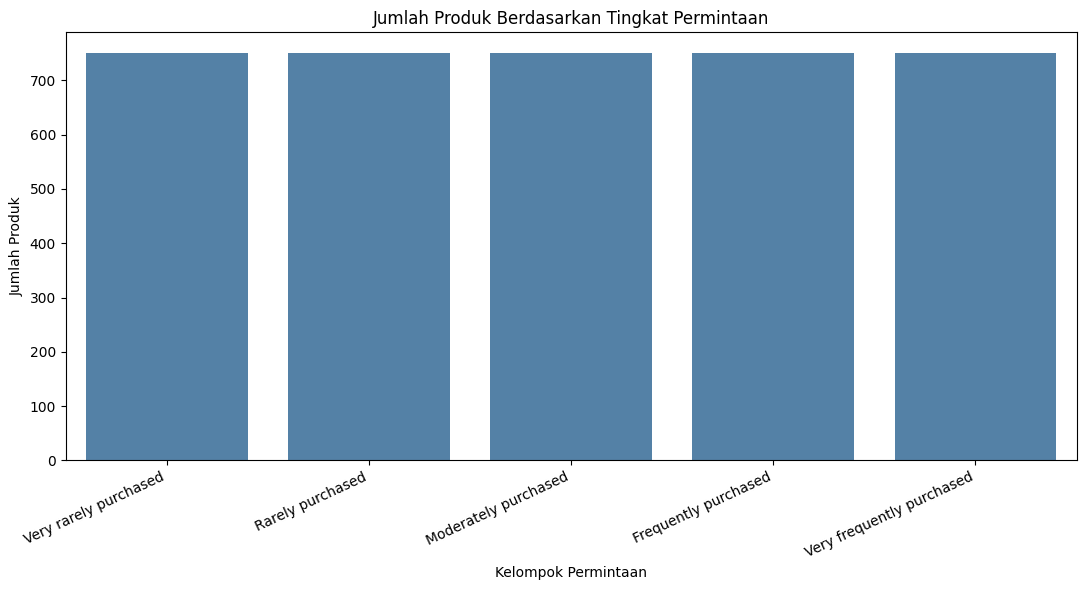

In [ ]:
plt.figure(figsize=(11, 6))
sns.countplot(
    data=produk,
    x="Kelompok_Permintaan",
    order=label_produk,
    color="steelblue"
)
plt.title("Jumlah Produk Berdasarkan Tingkat Permintaan")
plt.xlabel("Kelompok Permintaan")
plt.ylabel("Jumlah Produk")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### 7. Segmentasi Pelanggan Menggunakan Analisis RF (Recency & Frequency)
Menentukan tanggal acuan transaksi terakhir untuk menghitung nilai *Recency* (selang waktu sejak pembelian terakhir). Pelanggan kemudian dikelompokkan ke dalam segmen seperti *Inactive*, *Occasional*, *Active*, atau *Loyal* berdasarkan keaktifan transaksi mereka.

In [ ]:
tanggal_acuan = dataset["Date"].max()
print("Tanggal acuan:", tanggal_acuan.date())

Tanggal acuan: 2019-12-09


In [ ]:
pelanggan = (
    dataset.groupby("CustomerNo", as_index=False)
    .agg(
        Frekuensi_Transaksi=("TransactionNo", "nunique"),
        Pembelian_Terakhir=("Date", "max"),
        Total_Unit_Dibeli=("Quantity", "sum")
    )
)

In [ ]:
pelanggan["Recency_Hari"] = (
    tanggal_acuan - pelanggan["Pembelian_Terakhir"]
).dt.days

In [ ]:
def kelompok_pelanggan(row):
    if row["Recency_Hari"] > 90:
        return "Inactive customer"
    elif row["Frekuensi_Transaksi"] <= 2:
        return "Occasional customer"
    elif row["Frekuensi_Transaksi"] <= 5:
        return "Active customer"
    else:
        return "Loyal customer"

pelanggan["Segmen_Pelanggan"] = pelanggan.apply(
    kelompok_pelanggan,
    axis=1
)

urutan_segmen = [
    "Inactive customer",
    "Occasional customer",
    "Active customer",
    "Loyal customer"
]


In [ ]:
ringkasan_pelanggan = (
    pelanggan.groupby("Segmen_Pelanggan")
    .agg(
        Jumlah_Pelanggan=("CustomerNo", "count"),
        Median_Transaksi=("Frekuensi_Transaksi", "median"),
        Rata_Rata_Transaksi=("Frekuensi_Transaksi", "mean"),
        Median_Recency=("Recency_Hari", "median")
    )
    .reindex(urutan_segmen)
    .reset_index()
)

ringkasan_pelanggan["Persentase_Pelanggan"] = (
    ringkasan_pelanggan["Jumlah_Pelanggan"] /
    len(pelanggan) * 100
).round(2)

ringkasan_pelanggan[
    "Rata_Rata_Transaksi"
] = ringkasan_pelanggan[
    "Rata_Rata_Transaksi"
].round(2)

print("\nRingkasan Pengelompokan Pelanggan")
print(ringkasan_pelanggan.to_string(index=False))


Ringkasan Pengelompokan Pelanggan
   Segmen_Pelanggan  Jumlah_Pelanggan  Median_Transaksi  Rata_Rata_Transaksi  Median_Recency  Persentase_Pelanggan
  Inactive customer              1681               1.0                 1.85           203.0                 35.63
Occasional customer              1173               1.0                 1.49            37.0                 24.86
    Active customer               976               4.0                 3.80            26.0                 20.69
     Loyal customer               888               9.0                12.64            12.0                 18.82


### 8. Visualisasi Distribusi Segmen Pelanggan

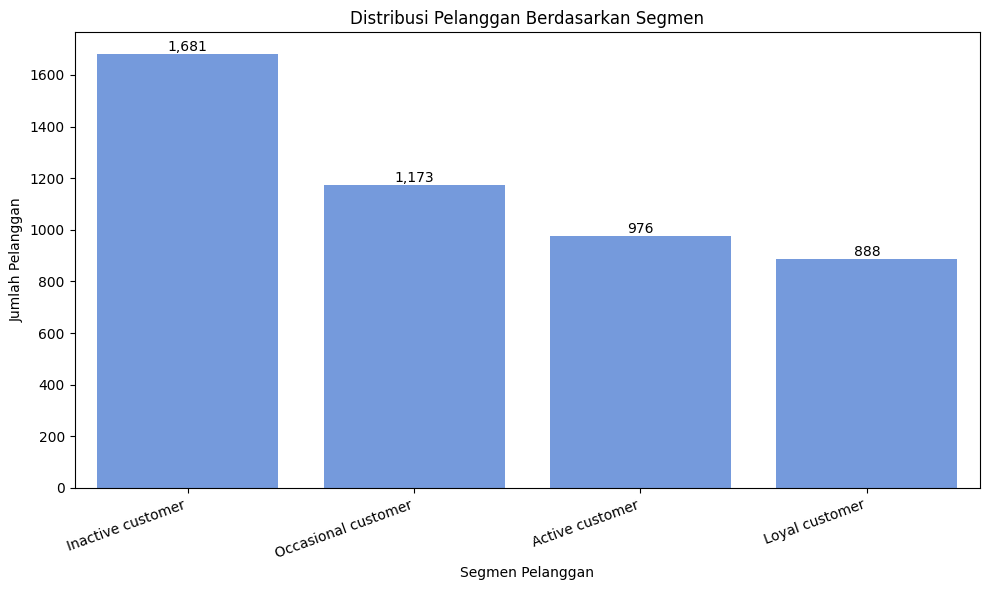

In [ ]:
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=pelanggan,
    x="Segmen_Pelanggan",
    order=urutan_segmen,
    color="cornflowerblue"
)

# Menampilkan jumlah di atas setiap batang
for bar in ax.patches:
    ax.annotate(
        f"{int(bar.get_height()):,}",
        (bar.get_x() + bar.get_width() / 2,
         bar.get_height()),
        ha="center",
        va="bottom"
    )

plt.title("Distribusi Pelanggan Berdasarkan Segmen")
plt.xlabel("Segmen Pelanggan")
plt.ylabel("Jumlah Pelanggan")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### 9. Ekspor Dataset

In [ ]:
# Menambahkan kategori produk ke data raw
dataset["Kelompok_Permintaan"] = dataset["ProductNo"].map(
    produk.set_index("ProductNo")["Kelompok_Permintaan"]
)

# Menambahkan kategori pelanggan ke data raw
dataset["Segmen_Pelanggan"] = dataset["CustomerNo"].map(
    pelanggan.set_index("CustomerNo")["Segmen_Pelanggan"]
)


df["Recency_Hari"] = df["CustomerNo"].map(
    pelanggan.set_index("CustomerNo")["Recency_Hari"]
)

# Menyimpan data raw beserta hasil pengelompokan
dataset.to_csv(
    "Sales_Transaction_with_Segmentation.csv",
    index=False,
    encoding="utf-8-sig"
)


In [ ]:
datahasil = pd.read_csv('/content/Sales_Transaction_with_Segmentation.csv')
datahasil.head()

,TransactionNo,Date,ProductNo,ProductName,Price,Quantity,CustomerNo,Country,Kelompok_Permintaan,Segmen_Pelanggan,Recency_Hari
0,581482,2019-12-09,22485,Set Of 2 Wooden Market Crates,21.47,12,17490,United Kingdom,Moderately purchased,Loyal customer,0
1,581475,2019-12-09,22596,Christmas Star Wish List Chalkboard,10.65,36,13069,United Kingdom,Very frequently purchased,Loyal customer,0
2,581475,2019-12-09,23235,Storage Tin Vintage Leaf,11.53,12,13069,United Kingdom,Frequently purchased,Loyal customer,0
3,581475,2019-12-09,23272,Tree T-Light Holder Willie Winkie,10.65,12,13069,United Kingdom,Moderately purchased,Loyal customer,0
4,581475,2019-12-09,23239,Set Of 4 Knick Knack Tins Poppies,11.94,6,13069,United Kingdom,Frequently purchased,Loyal customer,0


In [ ]:
print(datahasil.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 527764 entries, 0 to 527763
Data columns (total 11 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   TransactionNo        527764 non-null  int64  
 1   Date                 527764 non-null  object 
 2   ProductNo            527764 non-null  object 
 3   ProductName          527764 non-null  object 
 4   Price                527764 non-null  float64
 5   Quantity             527764 non-null  int64  
 6   CustomerNo           527764 non-null  int64  
 7   Country              527764 non-null  object 
 8   Kelompok_Permintaan  527764 non-null  object 
 9   Segmen_Pelanggan     527764 non-null  object 
 10  Recency_Hari         527764 non-null  int64  
dtypes: float64(1), int64(4), object(6)
memory usage: 44.3+ MB
None
